# !! Must Run on lumimod004 !! 

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

# Matplotlib config
#============================
FIGPATH  = ''
FIG_W = 8
FIG_H = 6



for key in plt.rcParams.keys():
    if 'date.auto' in key:
        plt.rcParams[key] = "%H:%M"
#============================

# Local imports
#------------------------------------------------
import sys
sys.path.append('/home/phbelang/abp/WireDAQ')
sys.path.append('/home/phbelang/abp/WireDAQ/Executables/py_wireDAQ/fillingstudies')
import WireDAQ.PandasPlus           # Make sure this import is after pandas
import WireDAQ.Constants as cst
import WireDAQ.NXCALS as nx
import WireDAQ.Parser as parser
import WireDAQ.Efficiency as eff


# Creating NXCALS variable containers
#------------------------------------------------
wires     = {'B1': [nx.NXCALSWire(loc = loc) for loc in ['L1B1','L5B1']],
             'B2': [nx.NXCALSWire(loc = loc) for loc in ['R1B2','R5B2']]}
beams     = [nx.NXCALSBeam(name) for name in ['B1','B2']]
B1,B2     = beams
LHC       = nx.NXCALSLHC()
b_slots   = np.arange(3564)
#------------------------------------------------


# Setting default values
#------------------------------------------------
_data_path   = '/eos/project/l/lhc-lumimod/LuminosityFollowUp/2023/rawdata'


# Importing fill metadata
#==========================================
_df_list = []
for state in ['on', 'off']:
    _df = pd.read_pickle(f'/home/phbelang/abp/WireDAQ/filter_wires_{state}.pkl')
    _df.insert(0, 'Wires', state.upper())
    _df_list.append(_df)
fill_df = pd.concat(_df_list).sort_index()
#==========================================


>>> Loading nx2pd.py version of 24.10.2022 @ 03:17PM



# OVERVIEW PLOT

## Loading data

In [25]:
# Loading data
#------------------------------------------------
fill_to_exclude = []
fill_to_include = ['9035']#list(fill_df.index.astype('str'))

dt         = 10*60
beamMode   = 'STABLE'
variables  = [wires['B2'][0]['I']]
variables += [beam['bb_Intensity'] for beam in beams]
variables += [beam['Intensity'] for beam in beams]
variables += [beam['Nb'] for beam in beams]
variables += [LHC.Luminosity['ATLAS'],LHC.Xing['IP5'],LHC.betastar['IP5']]



# Loading
df_list = []
for _fill in fill_to_include:
    if _fill in fill_to_exclude:
        continue

    _df = parser.from_parquet2bin(fill=_fill,beamMode = beamMode,variables = variables,data_path= _data_path,dt = dt,keeptype=False)
    _df = parser.make_timestamps(_df)
    _df.insert(0,'Fill',_fill)

    if _fill == '8896':
        end_8896   = 1686511823662738432#pd.Timestamp('2023-06-11 21:30:00')
        start_8897 = 1686523523662738432#pd.Timestamp('2023-06-12 00:45:00')
    
        df_list.append(_df.loc[:end_8896])

        _df_cropped = _df.loc[start_8897:]
        _df_cropped.loc[:,'Fill'] = '8897'
        _df_cropped.loc[:,'Time'] -= _df_cropped['Time'].values[0]

        df_list.append(_df_cropped)
    else:
        df_list.append(_df)

database = pd.concat(df_list)
#------------------------------------------------

# Adding missing 8897 fill
_add = fill_df.loc[8896].copy()
_add.name = 8897
fill_df = pd.concat([fill_df,_add.to_frame().T]).sort_index()



# Testing

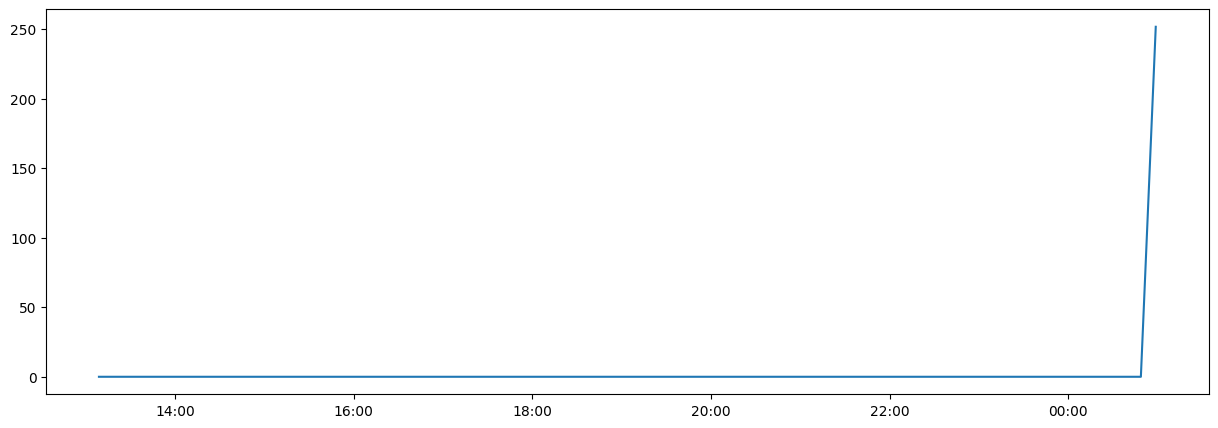

In [28]:
# df = database.groupby('Fill').get_group('8877')
fill = '9035'
df   = database.groupby('Fill').get_group(fill)

plt.figure(figsize=(15,5))
# df.nxPlot('Timestamp',LHC.betastar['IP5'])
# df.nxPlot('Timestamp',B1.Intensity)
# df.nxPlot('Timestamp',B2.Intensity,color='C3')
df.nxPlot('Timestamp',wires['B2'][0]['I'])

# if fill_df.loc[int(fill),'Wires'] == 'ON':
#     # Values of ON ts
#     start_ts,stop_ts = df['Timestamp'].min(),df['Timestamp'].max()
#     wire_ON_ts = df.loc[df[wires['B2'][0]['I']]>340,'Timestamp'].values

#     wire_start = wire_ON_ts.min()
#     wire_stop  = wire_ON_ts.max()
# # 
#     # plt.axvline(wire_start)
#     # plt.axvline(wire_stop)


# # plt.axvline(pd.Timestamp('2023-06-11 21:30:00'))
# # plt.axvline(pd.Timestamp('2023-06-12 00:45:00'))
# plt.axvline(start_ts)
# plt.axvline(stop_ts)

In [19]:

# Extracting pattern from intensity
#=====================================================
filled_b_slots = {}
for beam in beams:
    
    # Only looking at after max of intensity
    bb_I    = _df[beam['bb_Intensity']].dropna()
    max_loc = bb_I.apply(lambda line: np.sum(line)).argmax()
    bb_I    = bb_I.iloc[max_loc:]


    # Taking bb intensity just after max signal and then 1/4 of the way
    probe1 = bb_I.iloc[2-1:2+1].mean(axis=0)
    probe2 = bb_I.iloc[len(bb_I)//4-1:len(bb_I)//4+1].mean(axis=0)


    assert(np.all((probe1>1e9) == (probe2>1e9))), 'Error on the filling scheme'

    filled_b_slots[beam.name] = (probe1>1e9).astype(int)
#=====================================================

AssertionError: Error on the filling scheme

In [32]:
sum(filled_b_slots['B1'])

2464

In [23]:
sum(probe1>1e10)

2464

In [21]:
sum(probe1>1e10)

2464

In [22]:
probe1[probe2!=0]

array([1.5102732e+11, 1.5566781e+11, 1.5779738e+11, ..., 1.3598942e+11,
       1.3814279e+11, 1.2528478e+11], dtype=float32)

In [20]:
probe1[probe1!=0]

array([1.5102732e+11, 1.5566781e+11, 1.5779738e+11, ..., 1.3598942e+11,
       1.3814279e+11, 1.2528478e+11], dtype=float32)

(0.0, 200.0)

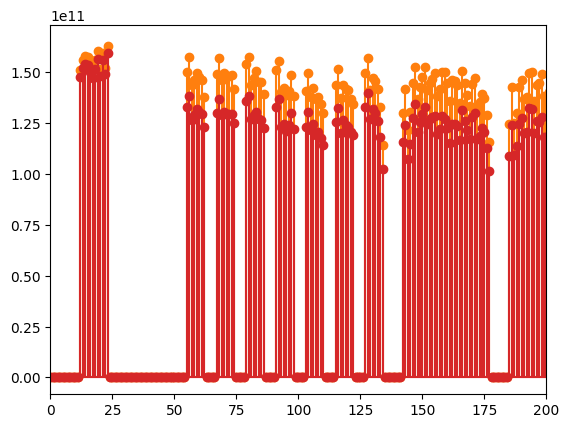

In [19]:
plt.figure()
plt.stem(probe1,linefmt='C1', markerfmt=None, basefmt=None)
plt.stem(probe2,linefmt='C3', markerfmt=None, basefmt=None)
plt.xlim(0,200)

In [9]:
probe1

array([0., 0., 0., ..., 0., 0., 0.], dtype=float32)

In [49]:
df.loc[:end_8896]

,Fill,Timestamp,Time,RPMC.UL16.RBBCW.R1B2:I_MEAS,LHC.BCTDC.A6R4.B2:BEAM_INTENSITY,LHC.BQM.B2:NO_BUNCHES,ATLAS:LUMI_TOT_INST,LhcStateTracker:LHCBEAM:IP5-XING-H-MURAD:target,HX:BETASTAR_IP5
unix,,,,,,,,,
1686482783662738432,8896,2023-06-11 13:26:23.662738432,0.0,-0.001314,3.735683e+14,2358.000000,12734.918945,135.0,120.0
1686482843662738432,8896,2023-06-11 13:27:23.662738432,60.0,-0.002912,3.731508e+14,2358.000000,12675.505859,135.0,120.0
1686482903662738432,8896,2023-06-11 13:28:23.662738432,120.0,0.001570,3.724336e+14,2358.000000,12608.460938,135.0,120.0
1686482963662738432,8896,2023-06-11 13:29:23.662738432,180.0,-0.001922,3.719208e+14,2358.000000,12643.615234,135.0,120.0
1686483023662738432,8896,2023-06-11 13:30:23.662738432,240.0,-0.000609,3.712039e+14,2358.000000,12674.801758,135.0,120.0
...,...,...,...,...,...,...,...,...,...
1686511583662738432,8896,2023-06-11 21:26:23.662738432,28800.0,350.002533,2.527862e+14,2358.000000,15750.554688,160.0,30.0
1686511643662738432,8896,2023-06-11 21:27:23.662738432,28860.0,349.996521,2.526119e+14,2358.000000,15729.879883,160.0,30.0
1686511703662738432,8896,2023-06-11 21:28:23.662738432,28920.0,349.997833,2.524354e+14,2358.000000,15696.617188,160.0,30.0


In [63]:

_df_cropped

,Fill,Timestamp,Time,RPMC.UL16.RBBCW.R1B2:I_MEAS,LHC.BCTDC.A6R4.B2:BEAM_INTENSITY,LHC.BQM.B2:NO_BUNCHES,ATLAS:LUMI_TOT_INST,LhcStateTracker:LHCBEAM:IP5-XING-H-MURAD:target,HX:BETASTAR_IP5
unix,,,,,,,,,
1686523523662738432,8897,2023-06-12 00:45:23.662738432,0.0,0.000392,3.701238e+14,2358.000000,9098.590820,135.0,120.0
1686523583662738432,8897,2023-06-12 00:46:23.662738432,60.0,0.001760,3.698638e+14,2358.000000,2728.201416,135.0,120.0
1686523643662738432,8897,2023-06-12 00:47:23.662738432,120.0,0.000799,3.696481e+14,2358.000000,3300.412109,135.0,120.0
1686523703662738432,8897,2023-06-12 00:48:23.662738432,180.0,-0.000630,3.694059e+14,2358.000000,9084.992188,135.0,120.0
1686523763662738432,8897,2023-06-12 00:49:23.662738432,240.0,0.000726,3.691505e+14,2358.000000,5017.727051,135.0,120.0
...,...,...,...,...,...,...,...,...,...
1686560783662738432,8897,2023-06-12 11:06:23.662738432,37260.0,349.999451,4.591055e+13,410.086957,10544.471680,160.0,7.0
1686560843662738432,8897,2023-06-12 11:07:23.662738432,37320.0,350.001068,3.896215e+09,0.000000,NaN,160.0,0.0
1686560903662738432,8897,2023-06-12 11:08:23.662738432,37380.0,350.000275,4.000125e+09,0.000000,NaN,160.0,0.0


In [47]:
df[df['Timestamp']>pd.Timestamp('2023-06-12 00:45:00')]

,Fill,Timestamp,Time,RPMC.UL16.RBBCW.R1B2:I_MEAS,LHC.BCTDC.A6R4.B2:BEAM_INTENSITY,LHC.BQM.B2:NO_BUNCHES,ATLAS:LUMI_TOT_INST,LhcStateTracker:LHCBEAM:IP5-XING-H-MURAD:target,HX:BETASTAR_IP5
unix,,,,,,,,,
1686523523662738432,8896,2023-06-12 00:45:23.662738432,40740.0,0.000392,3.701238e+14,2358.000000,9098.590820,135.0,120.0
1686523583662738432,8896,2023-06-12 00:46:23.662738432,40800.0,0.001760,3.698638e+14,2358.000000,2728.201416,135.0,120.0
1686523643662738432,8896,2023-06-12 00:47:23.662738432,40860.0,0.000799,3.696481e+14,2358.000000,3300.412109,135.0,120.0
1686523703662738432,8896,2023-06-12 00:48:23.662738432,40920.0,-0.000630,3.694059e+14,2358.000000,9084.992188,135.0,120.0
1686523763662738432,8896,2023-06-12 00:49:23.662738432,40980.0,0.000726,3.691505e+14,2358.000000,5017.727051,135.0,120.0
...,...,...,...,...,...,...,...,...,...
1686560783662738432,8896,2023-06-12 11:06:23.662738432,78000.0,349.999451,4.591055e+13,410.086957,10544.471680,160.0,7.0
1686560843662738432,8896,2023-06-12 11:07:23.662738432,78060.0,350.001068,3.896215e+09,0.000000,NaN,160.0,0.0
1686560903662738432,8896,2023-06-12 11:08:23.662738432,78120.0,350.000275,4.000125e+09,0.000000,NaN,160.0,0.0


In [73]:
stop_ts-start_ts

Timedelta('0 days 21:44:00')

In [58]:
df['Timestamp'].min()

Timestamp('2023-06-02 00:04:19.321238528')

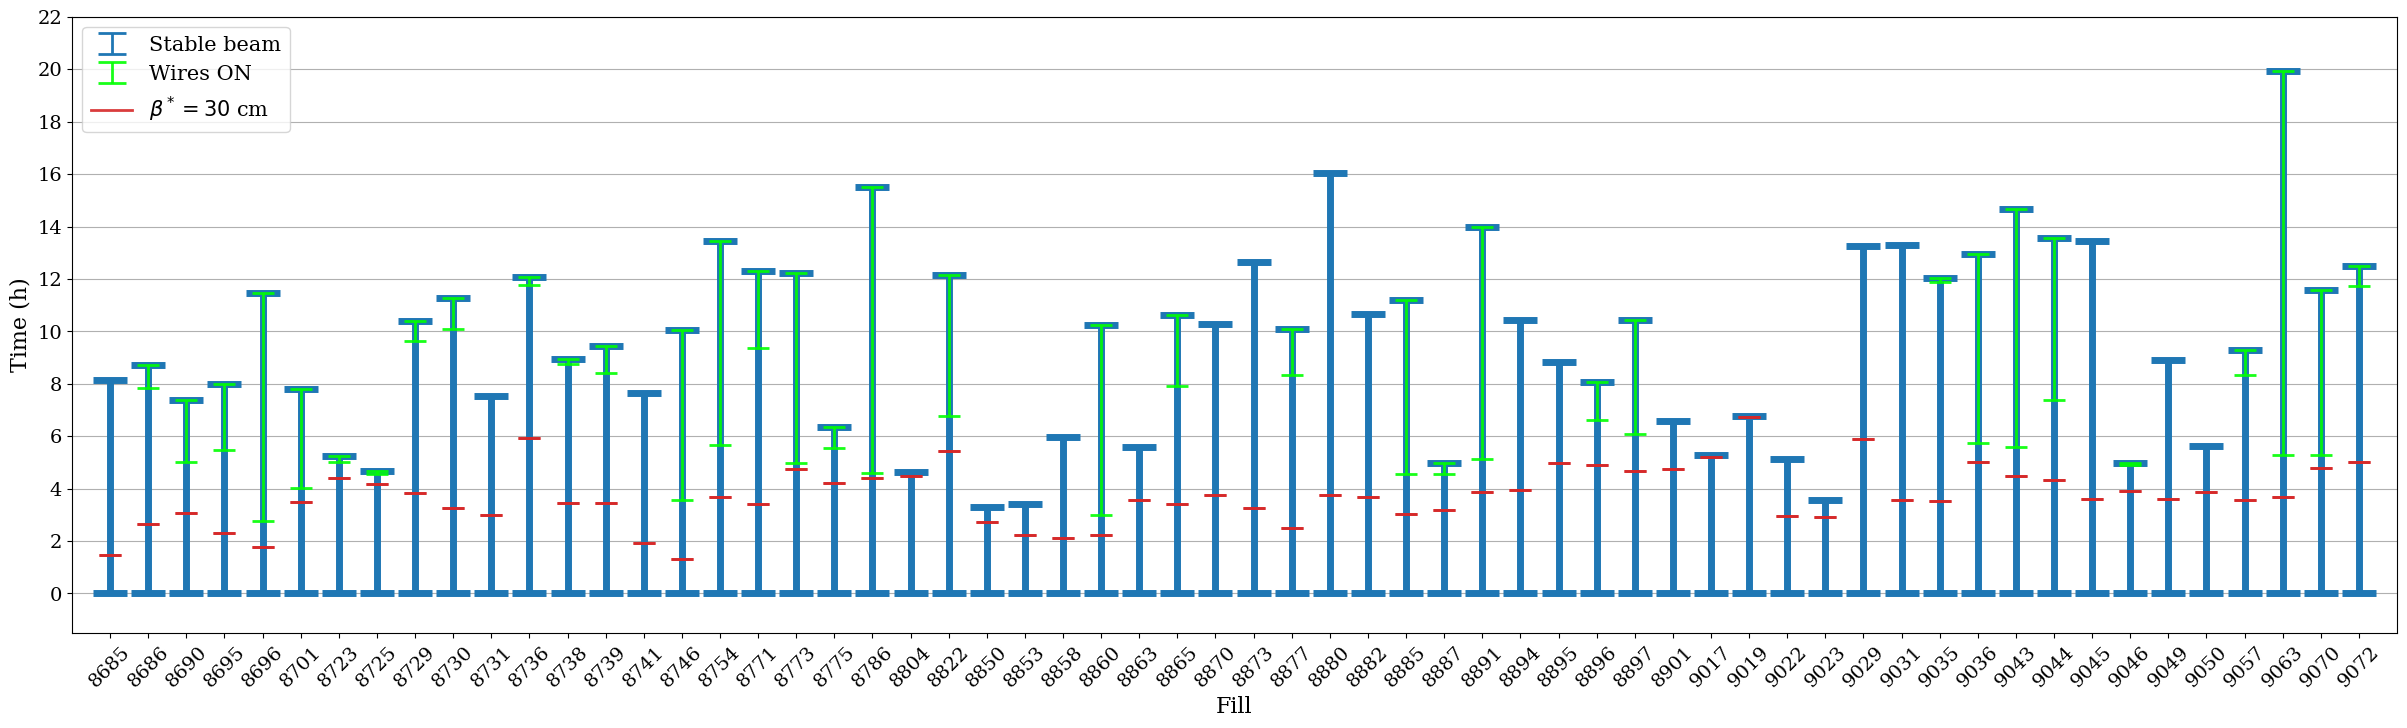

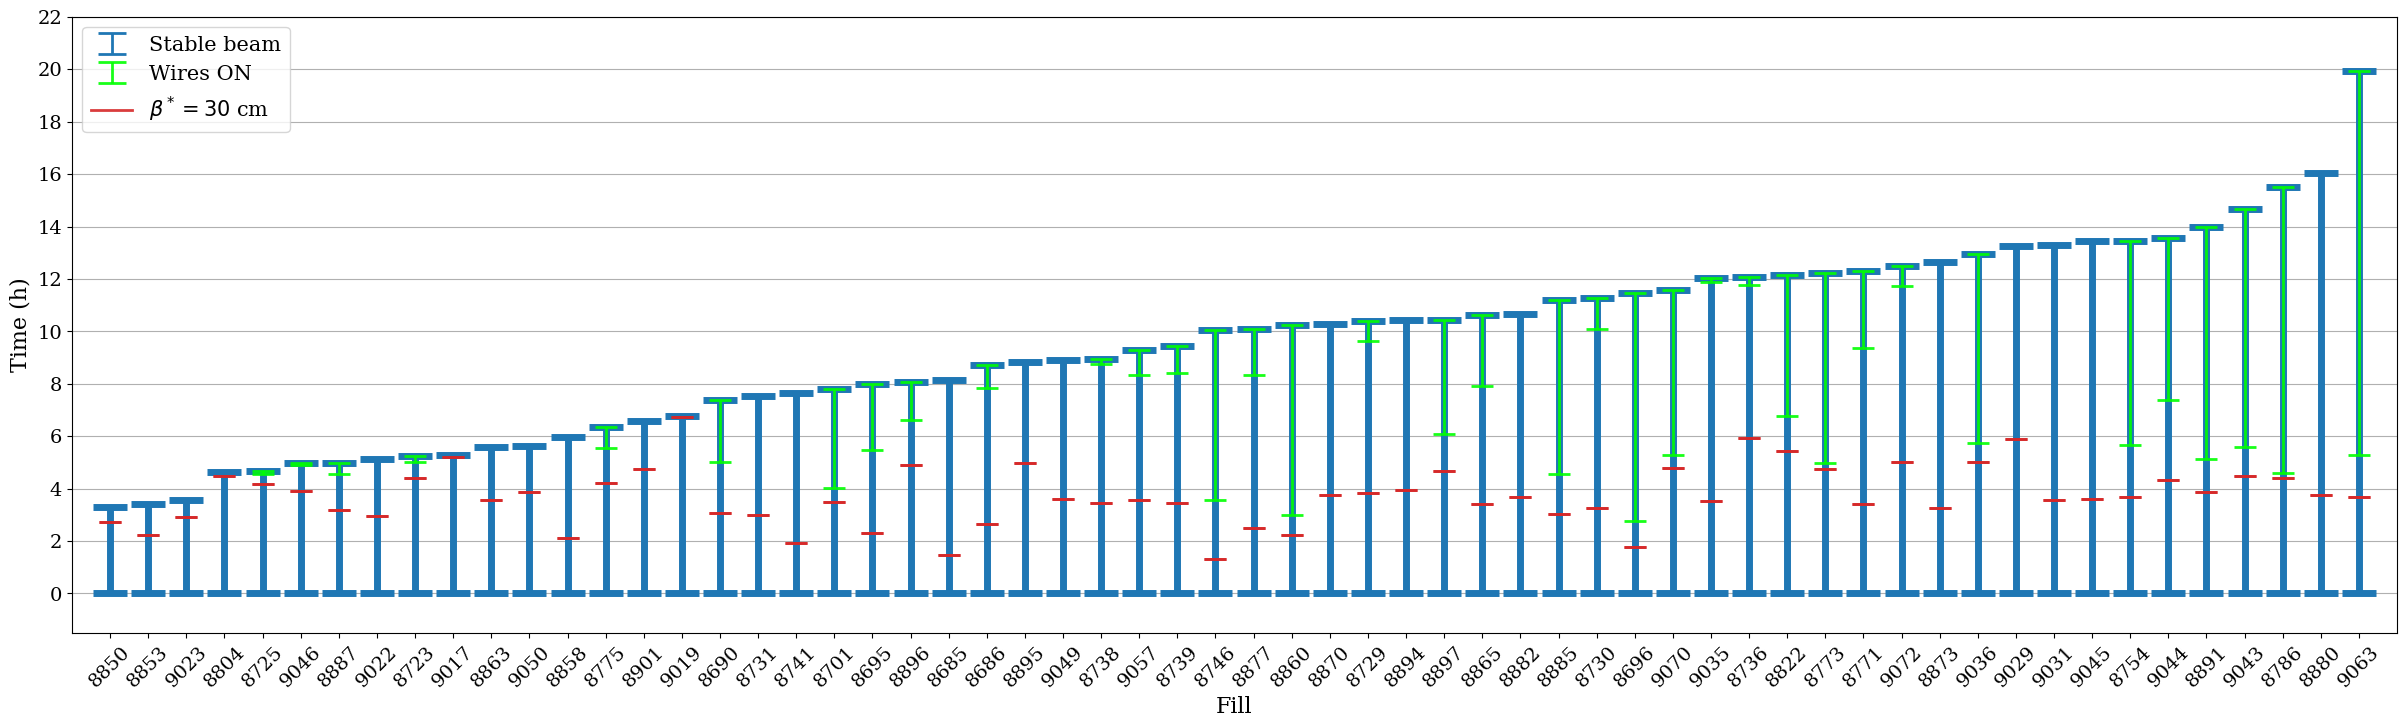

In [141]:

# def plot_fill_time_info(x):
#     fill_length = (stop_ts-start_ts).seconds/3600
#     plt.errorbar(x, [0], yerr=[[0],[fill_length]],ecolor='C0', 
#                                     elinewidth=5, 
#                                     capsize=12,
#                                     capthick = 5,alpha=1)

#     wire_time = (wire_start-start_ts).seconds/3600
#     wire_ramp = (wire_stop-wire_start).seconds/3600
#     plt.errorbar(x, [wire_time], yerr=[[0],[wire_ramp]],ecolor='lime', 
#                                     elinewidth=2, 
#                                     capsize=8,
#                                     capthick = 2,alpha=0.9)
#     beta_time = (beta_ts - start_ts).seconds/3600                           
#     plt.errorbar(x, [beta_time], yerr=[[0],[0]],ecolor='C3', 
#                                     elinewidth=2, 
#                                     capsize=8,
#                                     capthick = 2,alpha=0.9)



plt.figure(figsize=(30,8))


grouped = database.groupby('Fill')
xloc        = -1
fill_shown  = []
fill_length = []
for FILL, df in grouped:

    xloc += 1
    fill_shown.append(FILL)

    # Values of ON ts
    start_ts,stop_ts = df['Timestamp'].min(),df['Timestamp'].max()
    wire_ON_ts = df.loc[df[wires['B2'][0]['I']]>340,'Timestamp']
    beta_ts    = df[(df[LHC.betastar['IP5']]<32)&(df['Timestamp']>start_ts )]['Timestamp'].min()


    # Plotting Stable beam
    #=======================================================
    _length = (stop_ts-start_ts).seconds/3600
    fill_length.append(_length)
    plt.errorbar(xloc, [0], yerr=[[0],[_length]],ecolor='C0', 
                                    elinewidth=5, 
                                    capsize=12,
                                    capthick = 5,alpha=1)


    # Plotting wires
    if fill_df.loc[int(FILL),'Wires'] == 'ON':
        wire_start = wire_ON_ts.min()
        wire_stop  = wire_ON_ts.max()
        wire_time = (wire_start-start_ts).seconds/3600
        wire_ramp = (wire_stop-wire_start).seconds/3600
        plt.errorbar(xloc, [wire_time], yerr=[[0],[wire_ramp]],ecolor='lime', 
                                        elinewidth=2, 
                                        capsize=8,
                                        capthick = 2,alpha=0.9)

    # Plotting beta*
    beta_time = (beta_ts - start_ts).seconds/3600                           
    plt.errorbar(xloc, [beta_time], yerr=[[0],[0]],ecolor='C3', 
                                    elinewidth=2, 
                                    capsize=8,
                                    capthick = 2,alpha=0.9)


plt.xlim([-1,len(fill_shown)])
plt.ylim([-1.5,20])
plt.xticks(range(len(fill_shown)),labels=fill_shown,rotation=45,fontsize=14);
plt.yticks(np.arange(0,24,2),fontsize=14)
plt.grid(axis='y')
plt.ylabel('Time (h)',fontsize=16)
plt.xlabel('Fill',fontsize=16)


# LEGEND SHENANIGANS
#=======================================================
plt.errorbar(-10, [0], yerr=[[0],[0]],fmt ='none',ecolor='C0',elinewidth=2,capsize=10,capthick = 2,alpha=1,  label='Stable beam')
plt.plot([np.nan],[np.nan],color='C3',alpha=0.9,lw=2,label = r'$\beta^* = 30$ cm')
plt.errorbar(-10, [0], yerr=[[0],[0]],fmt ='none',ecolor='lime',elinewidth=2,capsize=10,capthick = 2,alpha=0.9,label='Wires ON')
plt.legend()
#get handles and labels
handles, labels = plt.gca().get_legend_handles_labels()
order = [1,2,0]
plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order],fontsize=15,loc='upper left')
#=======================================================


plt.figure(figsize=(30,8))


grouped = database.groupby('Fill')
xloc        = -1
fill_shown  = []

sorted_order = np.array(fill_length).argsort()

for FILL in database.Fill.unique()[sorted_order]:

    df = grouped.get_group(FILL)

    xloc += 1
    fill_shown.append(FILL)

    # Values of ON ts
    start_ts,stop_ts = df['Timestamp'].min(),df['Timestamp'].max()
    wire_ON_ts = df.loc[df[wires['B2'][0]['I']]>340,'Timestamp']
    beta_ts    = df[(df[LHC.betastar['IP5']]<32)&(df['Timestamp']>start_ts )]['Timestamp'].min()


    # Plotting Stable beam
    #=======================================================
    _length = (stop_ts-start_ts).seconds/3600
    fill_length.append(_length)
    plt.errorbar(xloc, [0], yerr=[[0],[_length]],ecolor='C0', 
                                    elinewidth=5, 
                                    capsize=12,
                                    capthick = 5,alpha=1)


    # Plotting wires
    if fill_df.loc[int(FILL),'Wires'] == 'ON':
        wire_start = wire_ON_ts.min()
        wire_stop  = wire_ON_ts.max()
        wire_time = (wire_start-start_ts).seconds/3600
        wire_ramp = (wire_stop-wire_start).seconds/3600
        plt.errorbar(xloc, [wire_time], yerr=[[0],[wire_ramp]],ecolor='lime', 
                                        elinewidth=2, 
                                        capsize=8,
                                        capthick = 2,alpha=0.9)

    # Plotting beta*
    beta_time = (beta_ts - start_ts).seconds/3600                           
    plt.errorbar(xloc, [beta_time], yerr=[[0],[0]],ecolor='C3', 
                                    elinewidth=2, 
                                    capsize=8,
                                    capthick = 2,alpha=0.9)


plt.xlim([-1,len(fill_shown)])
plt.ylim([-1.5,20])
plt.xticks(range(len(fill_shown)),labels=fill_shown,rotation=45,fontsize=14);
plt.yticks(np.arange(0,24,2),fontsize=14)
plt.grid(axis='y')
plt.ylabel('Time (h)',fontsize=16)
plt.xlabel('Fill',fontsize=16)






    # wire_start,wire_stop = wireROI(df)
    # wire_start = wire_stop
    # wire_stop  = df[(df[wires['B2'][0]['I']]<290)&(df['Timestamp']>wire_start)]['Timestamp'].min()
    
    # start_ts   = df[df['HX:BMODE'] == 'STABLE']['Timestamp'].iloc[0]
    # stop_ts    = df[df[beams[0]['Luminosity']['ATLAS']]>1000]['Timestamp'].max()

    # if FILL == 8128:
    #     start_ts   = df[(df[beams[0]['Luminosity']['ATLAS']]>2500)&(df['Timestamp']>(stop_ts-pd.Timedelta(hours=10)))]['Timestamp'].min()
    
    # beta_ts    = df[(df['HX:BETASTAR_IP1']<32)&(df['Timestamp']>start_ts )]['Timestamp'].min()
    # wire_stop  = np.min([wire_stop,stop_ts]) 

    # if FILL == 8320:
    #     pass
    # else:
    #     plot_fill_time_info(xloc)
    # xloc += 1
    # fill_shown.append(FILL)


# ADDING DUMPS
#plt.plot(np.arange(1,fills_on.index(8102)+1+1),-0.75*np.ones(fills_on.index(8102)+1),'--o',color='C4',alpha=0.7,label='Commissioning')
#plt.plot([0,fills_on.index(8146)+1],[-0.75,-0.75],'X',ms=8,color='red',alpha=0.7,label='Dump')
# plt.plot([np.nan],[np.nan],'--o',color='C4',alpha=0.7,label='Commissioning')
# #plt.plot([np.nan],[np.nan],'X',ms=8,color='red',alpha=0.7,label='Dump')
# plt.plot([fill_shown.index(8320)],[-0.75],'X',ms=8,color='red',alpha=0.7,label='Dump')

# LEGEND SHENANIGANS
#=======================================================
plt.errorbar(-10, [0], yerr=[[0],[0]],fmt ='none',ecolor='C0',elinewidth=2,capsize=10,capthick = 2,alpha=1,  label='Stable beam')
plt.plot([np.nan],[np.nan],color='C3',alpha=0.9,lw=2,label = r'$\beta^* = 30$ cm')
plt.errorbar(-10, [0], yerr=[[0],[0]],fmt ='none',ecolor='lime',elinewidth=2,capsize=10,capthick = 2,alpha=0.9,label='Wires ON')
plt.legend()
#get handles and labels
handles, labels = plt.gca().get_legend_handles_labels()
order = [1,2,0]
plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order],fontsize=15,loc='upper left')
#=======================================================

# plt.xlim([-1,len(fill_shown)])
# plt.ylim([-1.5,20])
# plt.xticks(range(len(fill_shown)),labels=fill_shown,rotation=45,fontsize=14);
# plt.yticks(np.arange(0,22,2),fontsize=14)
# plt.grid(axis='y')
# plt.ylabel('Time (h)',fontsize=16)
# plt.xlabel('Fill',fontsize=16)

# plt.tight_layout()
# # plt.savefig('../Results_Lumi_V3/fill_overview.png',dpi=300)

# Sorted version


array([23, 24, 45, 21,  7, 53, 35, 44,  6, 42, 27, 55, 25, 19, 41, 43,  2,
       10, 14,  5,  3, 39,  0,  1, 38, 54, 12, 56, 13, 15, 31, 26, 29,  8,
       37, 40, 28, 33, 34,  9,  4, 58, 48, 11, 22, 18, 17, 59, 30, 49, 46,
       47, 52, 16, 51, 36, 50, 20, 32, 57])

array(['8850', '8853', '9023', '8804', '8725', '9046', '8887', '9022',
       '8723', '9017', '8863', '9050', '8858', '8775', '8901', '9019',
       '8690', '8731', '8741', '8701', '8695', '8896', '8685', '8686',
       '8895', '9049', '8738', '9057', '8739', '8746', '8877', '8860',
       '8870', '8729', '8894', '8897', '8865', '8882', '8885', '8730',
       '8696', '9070', '9035', '8736', '8822', '8773', '8771', '9072',
       '8873', '9036', '9029', '9031', '9045', '8754', '9044', '8891',
       '9043', '8786', '8880', '9063'], dtype=object)

In [121]:
df.loc[df[wires['B2'][0]['I']]>340,'Timestamp'].max()

Timestamp('2023-04-30 05:01:01.380238592')